In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path

## Load Experiment

First, we load the experiment from the `results` folder. Each experiment is collected into a single `.parquet` file. Its rows contain recognition results for each configuration (combination) and each fold (flattened).

In [2]:
# Configuration which experiment should be loaded.
EXPERIMENT_NAME = "arcface_all_combinations"
RESULTS_PATH = Path("../../results")

In [3]:
# Load the experiment dataset.
EXPERIMENT_PATH = RESULTS_PATH / f"{EXPERIMENT_NAME}.parquet"
EXPERIMENT_DATA = pd.read_parquet(EXPERIMENT_PATH)
EXPERIMENT_DATA

,top-1,top-5,top-10,frame-top-1,fold,gallery_frame_anonymization,gallery_frame_aggregation,gallery_frame_embedding,gallery_embedding_aggregation,samples_frame_anonymization,samples_frame_aggregation,samples_frame_embedding,samples_embedding_aggregation,pipeline
0,0.956522,0.972332,0.974967,0.948644,1,none,video_none,arcface,video_none,none,video_none,arcface,video_none,frame
1,0.966216,0.978041,0.981419,0.958601,2,none,video_none,arcface,video_none,none,video_none,arcface,video_none,frame
2,0.959335,0.966728,0.968577,0.953381,3,none,video_none,arcface,video_none,none,video_none,arcface,video_none,frame
3,0.956522,0.963109,0.963109,0.956522,1,none,video_none,arcface,video_none,none,video_none,arcface,video_pooling_mean,frame
4,0.964527,0.972973,0.972973,0.964527,2,none,video_none,arcface,video_none,none,video_none,arcface,video_pooling_mean,frame
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
763,0.141892,0.285473,0.339527,0.141892,2,pixelation,video_none,arcface,identity_normweighted,pixelation,video_none,arcface,video_consensus_beta1,frame
764,0.109057,0.240296,0.301294,0.109057,3,pixelation,video_none,arcface,identity_normweighted,pixelation,video_none,arcface,video_consensus_beta1,frame
765,0.117260,0.259552,0.316206,0.117260,1,pixelation,video_none,arcface,identity_normweighted,pixelation,video_none,arcface,video_normweighted,frame
766,0.145270,0.288851,0.341216,0.145270,2,pixelation,video_none,arcface,identity_normweighted,pixelation,video_none,arcface,video_normweighted,frame


## Visualize accuracy

The following plots show the mean accuracy for each combination of (sample) anonymization method and (gallery) aggregation method. The anonymization method is applied both to the gallery and the samples.

The first plot aggregates the predictions based on their confidence before classifying. The latter does not and instead takes the mean accuracy over all single-frame classifications.

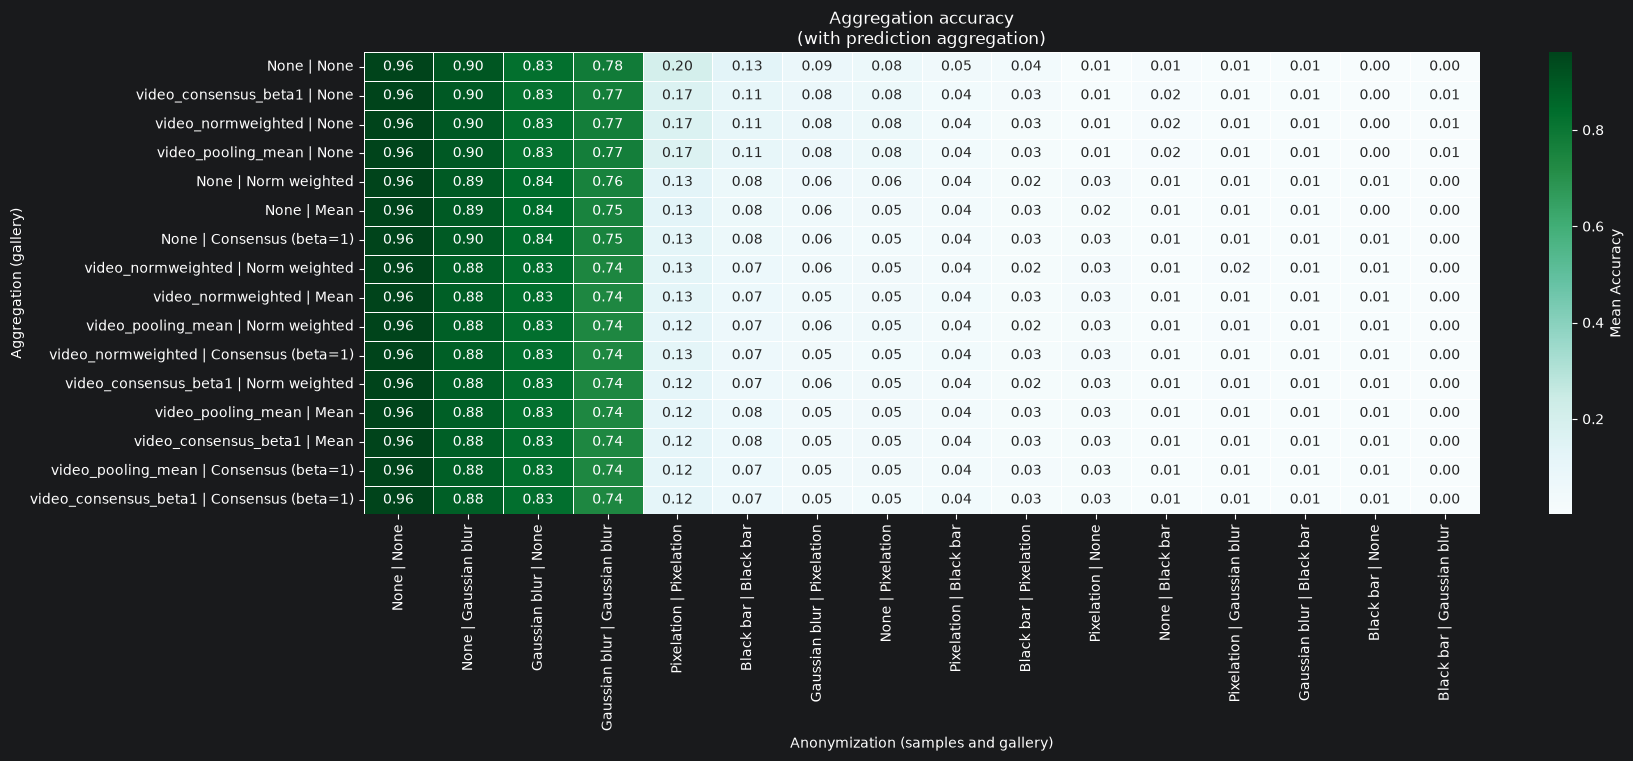

In [4]:
results = EXPERIMENT_DATA.copy()
results = results.replace(
    {
        "samples_frame_anonymization": {
            "none": "None",
            "gaussianblur": "Gaussian blur",
            "blackbar": "Black bar",
            "pixelation": "Pixelation",
        },
        "gallery_frame_anonymization": {
            "none": "None",
            "gaussianblur": "Gaussian blur",
            "blackbar": "Black bar",
            "pixelation": "Pixelation",
        },
        "samples_embedding_aggregation": {
            "video_none": "None",
            "identity_pooling_mean": "Mean",
            "identity_consensus_beta1": "Consensus (beta=1)",
            "identity_normweighted": "Norm weighted",
        },
        "gallery_embedding_aggregation": {
            "video_none": "None",
            "identity_pooling_mean": "Mean",
            "identity_consensus_beta1": "Consensus (beta=1)",
            "identity_normweighted": "Norm weighted",
        },
    }
)
results = results.assign(
    embedding_aggregation=results["samples_embedding_aggregation"] + " | " + results["gallery_embedding_aggregation"],
    frame_anonymization=results["samples_frame_anonymization"] + " | " + results["gallery_frame_anonymization"],
)

agg_order = results.groupby("embedding_aggregation")["top-1"].mean().sort_values(ascending=False).index
embedding_order = results.groupby("frame_anonymization")["top-1"].mean().sort_values(ascending=False).index

pivot_agg_embed = results.pivot_table(
    index="embedding_aggregation", columns="frame_anonymization", values="top-1", aggfunc="mean"
).loc[agg_order, embedding_order]

plt.figure(figsize=(18, 6))
sns.heatmap(
    pivot_agg_embed,
    annot=True,
    fmt=".2f",
    cmap="BuGn",
    cbar_kws={"label": "Mean Accuracy"},
    linewidths=0.5,
    linecolor="w",
)

plt.title("Aggregation accuracy\n(with prediction aggregation)")
plt.xlabel("Anonymization (samples and gallery)")
plt.ylabel("Aggregation (gallery)")
plt.show()

## Which leg does the anonymization hurt?

The plot below asks whether it matters *where* an anonymization method is applied. For each method
it compares the three pairings that involve only that one method — anonymized samples against a
clear gallery, clear samples against an anonymized gallery, and both legs anonymized — against the
dashed reference of the fully clear pairing. Pairings that mix two different methods are left out.

Each bar averages over all folds and all aggregation combinations (the same 48 rows per bar), the
error bar is their standard deviation.

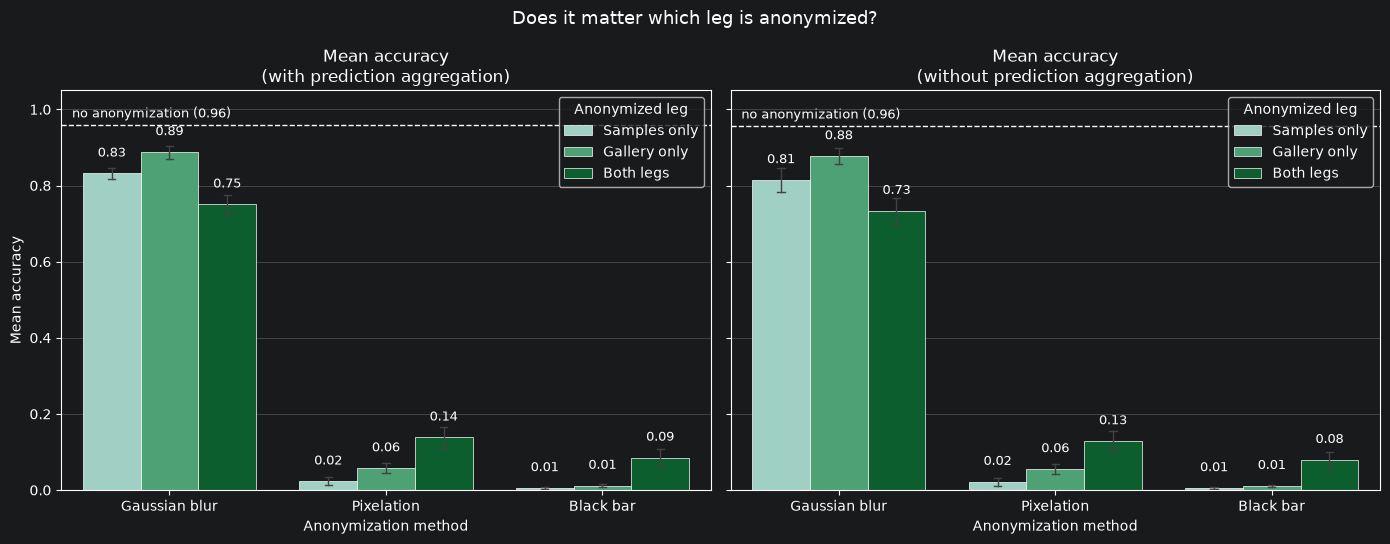

In [5]:
ANONYMIZATION_LABELS = {
    "gaussianblur": "Gaussian blur",
    "blackbar": "Black bar",
    "pixelation": "Pixelation",
}
# Which leg the anonymization was applied to, in the same BuGn ramp the heatmaps above use.
LEG_COLORS = dict(
    zip(
        ["Samples only", "Gallery only", "Both legs"],
        sns.color_palette("BuGn", n_colors=7)[2::2],
    )
)
METRICS = {
    "top-1": "with prediction aggregation",
    "frame-top-1": "without prediction aggregation",
}

samples = EXPERIMENT_DATA["samples_frame_anonymization"]
gallery = EXPERIMENT_DATA["gallery_frame_anonymization"]

# Keep the pairings that involve a single anonymization method: applied to the samples only, to
# the gallery only (the other leg stays clear), or to both legs. Mixed methods are dropped.
single_method = (samples == gallery) | (samples == "none") | (gallery == "none")
results = EXPERIMENT_DATA[single_method & ((samples != "none") | (gallery != "none"))].copy()

samples = results["samples_frame_anonymization"]
gallery = results["gallery_frame_anonymization"]
leg = pd.Series("Gallery only", index=results.index)
leg[gallery == "none"] = "Samples only"
leg[samples == gallery] = "Both legs"
results = results.assign(anonymization=samples.where(samples != "none", gallery).map(ANONYMIZATION_LABELS), leg=leg)

# Both clear: the reference the three anonymized conditions are read against.
clear = EXPERIMENT_DATA[
    (EXPERIMENT_DATA["samples_frame_anonymization"] == "none")
    & (EXPERIMENT_DATA["gallery_frame_anonymization"] == "none")
]

anonymization_order = results.groupby("anonymization")["top-1"].mean().sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, (metric, subtitle) in zip(axes, METRICS.items()):
    sns.barplot(
        data=results,
        x="anonymization",
        y=metric,
        hue="leg",
        order=anonymization_order,
        hue_order=list(LEG_COLORS),
        palette=LEG_COLORS,
        errorbar="sd",
        capsize=0.1,
        err_kws={"linewidth": 1},
        edgecolor="w",
        linewidth=0.5,
        ax=ax,
    )
    baseline = clear[metric].mean()
    ax.axhline(baseline, color="w", linestyle="--", linewidth=1)
    ax.text(-0.45, baseline + 0.012, f"no anonymization ({baseline:.2f})", va="bottom", ha="left", fontsize=9)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", fontsize=9, padding=10)

    ax.set_title(f"Mean accuracy\n({subtitle})")
    ax.set_xlabel("Anonymization method")
    ax.set_ylabel("Mean accuracy" if metric == "top-1" else "")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", linewidth=0.5, alpha=0.4)
    ax.set_axisbelow(True)
    ax.legend(title="Anonymized leg", loc="upper right")

fig.suptitle("Does it matter which leg is anonymized?", fontsize=13)
fig.tight_layout()
plt.show()